# Check metadata uncertainty, cutoffs and calibration: Subset data

Do the network's scores clearly improve on the spline? Do predicted risks match observed rates, and how much review work follows a cutoff aimed at finding 80% of malignant images?

[07_metadata_tuning.ipynb](07_metadata_tuning.ipynb) now reports tuning for four model families. The historical fixed-model sections below use saved network predictions from the archived stage 06 workflow. [06_metadata_neural_network.ipynb](06_metadata_neural_network.ipynb) reports the current fixed NN comparison. The appended assessment compares the fresh, versioned original fixed and tuned NN runs.

The saved run gives no clear average precision (AP) improvement from the network. The training-selected cutoff finds 79.7% of held-out malignant images while flagging 67.0% of all images. The reserved test labels are not used.

For metric definitions, see the [short concept guide](../concepts.md).


**Updated execution boundary:** the original fixed-model sections below reproduce saved development predictions, including their historical pooled summaries as secondary diagnostics. The added NN tuning assessment reports primary mean-fold comparisons separately. Executing this report starts no model training, creates no final bundle and does not read the reserved test.

**Version-2 reporting and evidence boundary:** the current added assessment uses the separately declared ROC-AUC-selected experiment, with mean outer-fold ROC-AUC primary and AP, log loss and Brier secondary. The fixed-model calibration, cutoff, subgroup and AP-led comparisons retained below are historical supporting analyses from the pre-migration report. Their maps and thresholds do not evaluate the new tuned network. The new paired ROC-AUC and secondary AP appendix follows those preserved sections; neither branch fits a final model or opens the reserved test.

## Context and methods

### Separate choosing a rule from assessing it

A fold is a group of patients; all their images stay together. For each of five outer folds:

1. Reserve its patients for assessment.
2. Within the four training folds, fit on three and predict the fourth, four times. These inner out-of-fold (OOF) scores are made without training on the scored patient.
3. Use only inner scores and labels for recalibration and cutoff selection.
4. Fit the spline on all four training folds, predict the outer patients, and assess the chosen rules there. Combine the five outer tables.

Recalibration is a logistic adjustment to the level and spread of probability estimates. Its settings are fixed, rather than chosen from outer results. Calibration asks whether estimates such as 3% agree with observed malignant rates among comparable cases. A score in [0,1] does not establish that agreement.

The cutoff is the score at or above which an image is flagged. Choose the highest inner cutoff meeting 80% recall, the share of malignant images found. This is an academic scenario; outer recall may be lower. Preprocessing is fitted entirely within training, and explicit checks enforce patient separation.

### Read performance and uncertainty together

Average precision (AP) was the primary ranking measure for these historical fixed-model diagnostics: higher means malignant images concentrate nearer the top. ROC-AUC measures how often a malignant image scores above a benign one; 0.5 is chance. Log loss and Brier score measure probability error; lower is better.

For uncertainty, bootstrap whole patients: repeatedly sample patients with replacement, keeping their images together. The middle 95% of resampled results forms an interval. Compare methods on the same draws to estimate their difference. These intervals keep saved predictions fixed, without retraining.

Results are per image, so patients with more images carry more weight. The reused folds have guided earlier choices; these checks cannot make the comparison an independent final test. Save the chosen model, cutoff and source fingerprints before any later final-test evaluation.


### 1. Set up the run

Use the historical three-run network predictions from the archived stage 06 workflow with `requirements-metadata.txt` and the project Python kernel. The next checks verify their data, code and prediction fingerprints before comparison. Executing these cells reads completed artifacts and writes new reports. The separate runners own model fitting; historical predictions and decisions remain unchanged.


In [2]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import sys

import joblib
import nbformat
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.metadata_model import (
    FEATURES, SPECIFICATION, file_sha256,
)
from melanoma_detection.metadata_evaluation import (
    calibration_bins, decision_metrics, patient_bootstrap, probability_metrics, validate_probabilities,
)
from melanoma_detection.metadata_validation import validate_metadata_frame

DATA_PATH = PROJECT_ROOT / "data/subset/processed/train_folds.csv"
NN_PATH = PROJECT_ROOT / "results/predictions/metadata_nn_oof_d1.csv"
NN_CONFIG_PATH = PROJECT_ROOT / "results/metrics/metadata_nn_run_config_d1.json"
from melanoma_detection.metadata_tuning_v2 import condition_directory, DEFAULT_RUN_ID
OUTPUT_ROOT = condition_directory(PROJECT_ROOT, "original", DEFAULT_RUN_ID) / "report" / "08_metadata_robustness"
FIGURES = OUTPUT_ROOT / "figures"
TABLES = OUTPUT_ROOT / "tables"
METRICS = OUTPUT_ROOT / "metrics"
PREDICTIONS = OUTPUT_ROOT / "predictions"
MODEL_DIR = OUTPUT_ROOT / "boundary_only"
for path in [FIGURES, TABLES, METRICS, PREDICTIONS, MODEL_DIR]:
    path.mkdir(parents=True, exist_ok=True)
TARGET_RECALL = 0.80
BOOTSTRAP_REPETITIONS = 2000
BOOTSTRAP_SEED = 42
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
INPUT_HASH = file_sha256(DATA_PATH)
print("Only development data:", DATA_PATH.relative_to(PROJECT_ROOT))
print("Input SHA256:", INPUT_HASH)

Only development data: data\subset\processed\train_folds.csv
Input SHA256: 4020a29a53b96943443e4d6173d35dabc6954fd5bd7d4d9db73a6b554a86a324


## Data

### 2. Check inputs and match images

Match predictions by image name and verify patient IDs, labels and folds. Check data, prediction and validation-code fingerprints; recorded filename relocations are accepted only when the executable method is otherwise preserved. This prevents comparisons with another dataset or changed method. The table confirms the development population.


In [3]:
train = validate_metadata_frame(pd.read_csv(DATA_PATH, dtype={"age_approx": "string", "target": "string"}))
nn_config = json.loads(NN_CONFIG_PATH.read_text(encoding="utf-8"))
if nn_config["input_sha256"] != INPUT_HASH:
    raise ValueError("NN predictions are stale. Rerun notebook 06 on these exact folds.")
if nn_config["prediction_sha256"] != file_sha256(NN_PATH):
    raise ValueError("NN predictions differ from their saved run configuration.")
from melanoma_detection.notebook_integrity import verify_recorded_notebook_code
nn_code_check = verify_recorded_notebook_code(
    PROJECT_ROOT, "notebooks/Subset/06_metadata_neural_network.ipynb",
    nn_config["notebook_path"], nn_config["code_sha256"],
)
if nn_config["validation_source_sha256"] != file_sha256(PROJECT_ROOT / nn_config["validation_source_path"]):
    raise ValueError("NN validation source changed after its saved run.")
nn_predictions = pd.read_csv(NN_PATH)
if nn_predictions.image_name.duplicated().any() or set(nn_predictions.image_name) != set(train.image_name):
    raise ValueError("NN predictions do not cover each development image exactly once.")
nn_predictions = nn_predictions.set_index("image_name").loc[train.image_name].reset_index()
for column in ["patient_id", "target", "fold"]:
    if not np.array_equal(train[column].to_numpy(), nn_predictions[column].to_numpy()):
        raise ValueError(f"NN identity mismatch: {column}")
display(pd.DataFrame([{
    "Images": len(train), "Patients": train.patient_id.nunique(),
    "Malignant images": int(train.target.sum()),
    "Patients with malignancy": int(train.groupby("patient_id").target.max().sum()),
    "Malignant image fraction": train.target.mean(),
}]).round(4))

,Images,Patients,Malignant images,Patients with malignancy,Malignant image fraction
0,6864,422,128,88,0.0186


## Results

### 3. Verify calibration and cutoffs selected using training patients

The raw spline keeps four cubic age knots and regularisation C=1. For every outer fold, only the inner training scores supply information for recalibration and cutoff selection. The saved audit table records the size and class counts of each partition.

The table below shows each training-selected cutoff beside its results on outer patients. Compare sensitivity (malignant images found), specificity (benign images left unflagged), precision (malignancy among flagged images) and the fraction flagged. These columns show why meeting a recall target can require many false alarms.


In [4]:
# Reuse immutable historical fixed-spline calibration and training-selected decisions.
outer_predictions = pd.read_csv(PROJECT_ROOT / "results/predictions/metadata_robustness_oof_d1.csv", float_precision="round_trip")
outer_predictions = outer_predictions.set_index("image_name").loc[train.image_name].reset_index()
split_audit = pd.read_csv(PROJECT_ROOT / "results/tables/metadata_robustness_split_audit_d1.csv")
for column in ["patient_id", "fold", "target"]:
    if not np.array_equal(outer_predictions[column], train[column]):
        raise ValueError("Historical robustness prediction identity changed.")
if not split_audit.patient_overlap.eq(0).all():
    raise ValueError("Patient overlap found.")
np.testing.assert_allclose(outer_predictions.p_spline_raw, nn_predictions.p_spline, atol=1e-10, rtol=1e-9)
for column in ["p_spline_raw", "p_spline_calibrated"]:
    validate_probabilities(train.target, outer_predictions[column])
for column in ["p_nn_seed_42", "p_nn_seed_142", "p_nn_seed_242", "p_nn_mean"]:
    validate_probabilities(train.target, nn_predictions[column])
np.testing.assert_allclose(nn_predictions.p_nn_mean, nn_predictions[["p_nn_seed_42", "p_nn_seed_142", "p_nn_seed_242"]].mean(axis=1), atol=1e-12)
outer_predictions.to_csv(PREDICTIONS / "metadata_robustness_oof_d1.csv", index=False)
split_audit.to_csv(TABLES / "metadata_robustness_split_audit_d1.csv", index=False)

fold_rows = []
for fold, rows in outer_predictions.groupby("fold"):
    for version, p_column, decision_column, threshold_column in [
        ("Raw spline", "p_spline_raw", "decision_raw", "raw_threshold"),
        ("Recalibrated spline", "p_spline_calibrated", "decision_calibrated", "calibrated_threshold"),
    ]:
        fold_rows.append({"fold": fold, "procedure": version, "training_selected_threshold": rows[threshold_column].iloc[0],
                          **probability_metrics(rows.target, rows[p_column]), **decision_metrics(rows.target, rows[decision_column])})
fold_metrics = pd.DataFrame(fold_rows)
fold_metrics.to_csv(METRICS / "metadata_robustness_fold_metrics_d1.csv", index=False)
display(fold_metrics[["fold", "procedure", "training_selected_threshold", "sensitivity", "specificity", "precision", "flagged_fraction"]].round(4))

,fold,procedure,training_selected_threshold,sensitivity,specificity,precision,flagged_fraction
0,0,Raw spline,0.0103,1.0000,0.1822,0.0222,0.8212
1,0,Recalibrated spline,0.0131,1.0000,0.1822,0.0222,0.8212
2,1,Raw spline,0.0115,0.6538,0.4042,0.0208,0.5969
3,1,Recalibrated spline,0.0130,0.6538,0.4042,0.0208,0.5969
4,2,Raw spline,0.0095,0.8077,0.4007,0.0252,0.6032
5,2,Recalibrated spline,0.0113,0.8077,0.4007,0.0252,0.6032
6,3,Raw spline,0.0102,0.8400,0.2125,0.0194,0.7885
7,3,Recalibrated spline,0.0118,0.8400,0.2125,0.0194,0.7885
8,4,Raw spline,0.0112,0.6923,0.4621,0.0243,0.5409
9,4,Recalibrated spline,0.0130,0.6923,0.4621,0.0243,0.5409


### 4. Read the patient-based comparison intervals

Draw 422 patients with replacement 2,000 times, keeping each person's images together. Compute all methods on each same draw and subtract the spline score. This paired comparison isolates a method difference within the sampled patients.

- **Left panel:** models are the rows and AP is horizontal. Blue dots show observed scores; lines show 95% patient-bootstrap intervals. Farther right is better.
- **Right panel:** the horizontal axis is network AP minus spline AP. Gold squares mark observed differences and lines show their paired intervals. Zero means no change; an interval crossing zero gives no clear direction. Prefer this paired view over comparing the overlap of separate score intervals.

The network mean's interval is [-0.0190, +0.0059], giving no clear AP improvement. These exploratory intervals hold predictions fixed and are not adjusted for multiple comparisons.


,model_name,reference_model,metric,estimate,ci_lower,ci_upper,n_valid
0,Raw spline,NaN,average_precision,0.0484,0.0325,0.0813,2000
1,Raw spline,NaN,roc_auc,0.6499,0.5752,0.7221,2000
4,Recalibrated spline,NaN,average_precision,0.0478,0.0327,0.0783,2000
5,Recalibrated spline,NaN,roc_auc,0.6460,0.5726,0.7186,2000
8,NN seed 42,NaN,average_precision,0.0458,0.0323,0.0707,2000
9,NN seed 42,NaN,roc_auc,0.6627,0.5933,0.7285,2000
12,NN seed 142,NaN,average_precision,0.0486,0.0335,0.0733,2000
13,NN seed 142,NaN,roc_auc,0.6743,0.6076,0.7378,2000
16,NN seed 242,NaN,average_precision,0.0461,0.0329,0.0711,2000
17,NN seed 242,NaN,roc_auc,0.6746,0.6075,0.7372,2000


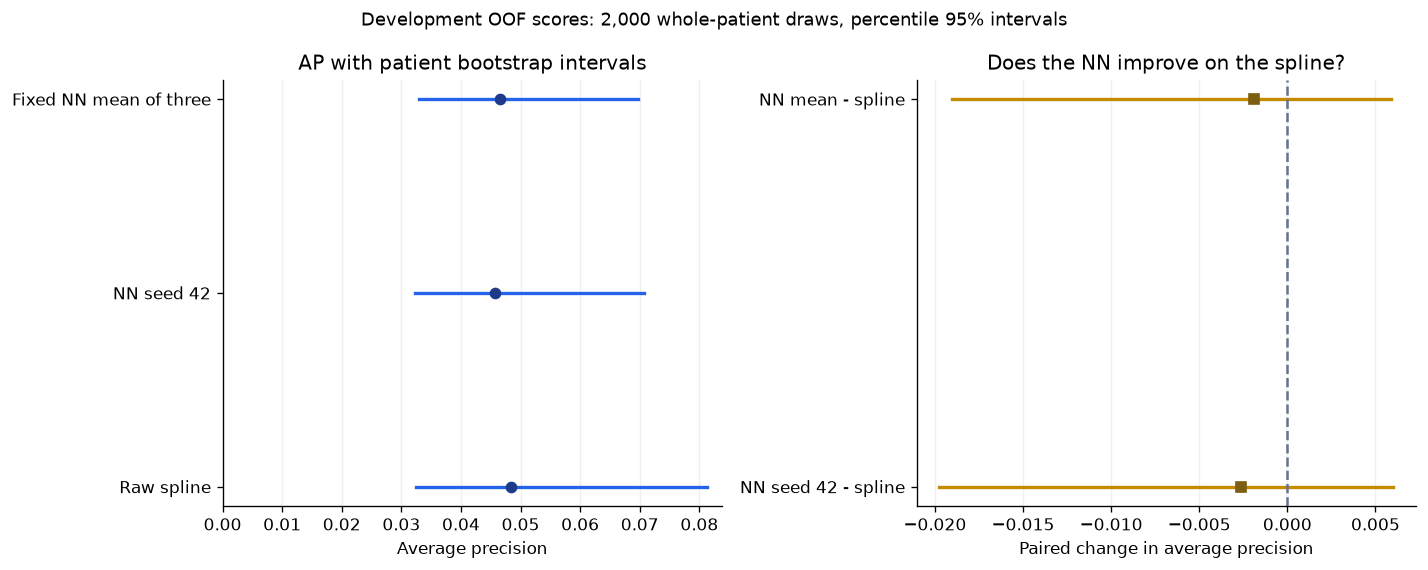

In [5]:
probability_sets = {
    "Raw spline": outer_predictions.p_spline_raw.to_numpy(),
    "Recalibrated spline": outer_predictions.p_spline_calibrated.to_numpy(),
    "NN seed 42": nn_predictions.p_nn_seed_42.to_numpy(),
    "NN seed 142": nn_predictions.p_nn_seed_142.to_numpy(),
    "NN seed 242": nn_predictions.p_nn_seed_242.to_numpy(),
    "Fixed NN mean of three": nn_predictions.p_nn_mean.to_numpy(),
}
intervals = patient_bootstrap(
    train.target, train.patient_id, probability_sets,
    n_bootstrap=BOOTSTRAP_REPETITIONS, seed=BOOTSTRAP_SEED,
    comparisons=[("Recalibrated spline", "Raw spline"), ("NN seed 42", "Raw spline"), ("Fixed NN mean of three", "Raw spline")],
)
intervals.to_csv(METRICS / "metadata_patient_bootstrap_d1.csv", index=False)
display(intervals.loc[intervals.metric.isin(["average_precision", "roc_auc"]),
                      ["model_name", "reference_model", "metric", "estimate", "ci_lower", "ci_upper", "n_valid"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
selected = ["Raw spline", "NN seed 42", "Fixed NN mean of three"]
for index, name in enumerate(selected):
    row = intervals[(intervals.model_name == name) & intervals.reference_model.isna() & (intervals.metric == "average_precision")].iloc[0]
    axes[0].plot([row.ci_lower, row.ci_upper], [index, index], color="#2563EB", linewidth=2)
    axes[0].plot(row.estimate, index, "o", color="#1E3A8A")
axes[0].set_yticks(range(len(selected)), selected)
axes[0].set_xlim(left=0)
axes[0].set_xlabel("Average precision")
axes[0].set_title("AP with patient bootstrap intervals")
for index, name in enumerate(["NN seed 42", "Fixed NN mean of three"]):
    row = intervals[(intervals.model_name == name) & (intervals.reference_model == "Raw spline") & (intervals.metric == "average_precision")].iloc[0]
    axes[1].plot([row.ci_lower, row.ci_upper], [index, index], color="#C58A00", linewidth=2)
    axes[1].plot(row.estimate, index, "s", color="#7C5E10")
axes[1].axvline(0, color="#64748B", linestyle="--")
axes[1].set_yticks([0, 1], ["NN seed 42 - spline", "NN mean - spline"])
axes[1].set_xlabel("Paired change in average precision")
axes[1].set_title("Does the NN improve on the spline?")
for axis in axes: axis.grid(axis="x", alpha=0.2)
fig.suptitle("Development OOF scores: 2,000 whole-patient draws, percentile 95% intervals", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_patient_bootstrap_d1.png", dpi=180, bbox_inches="tight")
plt.show()

### 5. Read calibration and score distributions

Group scores into five roughly equal-sized bins without splitting identical scores. Blue circles are the raw spline; gold squares are its training-only recalibrated version. Axis fractions such as 0.03 mean 3%.

- **Left: calibration.** Horizontal position is mean estimated probability; vertical position is observed malignant share. The dashed diagonal means agreement. Above it indicates underestimated risk; below it indicates overestimated risk. Vertical lines are 95% patient-bootstrap intervals for the observed rate, holding bins fixed. They do not describe uncertainty in horizontal position.
- **Right: score distribution.** Horizontal position is predicted probability; outline height counts images. Blue and gold show how recalibration moves the scores, most of which remain small.

Read the bin counts and error measures too. Few malignant cases make the curve noisy; Brier score and log loss reflect ranking as well as calibration. Recalibration is not automatically an improvement.


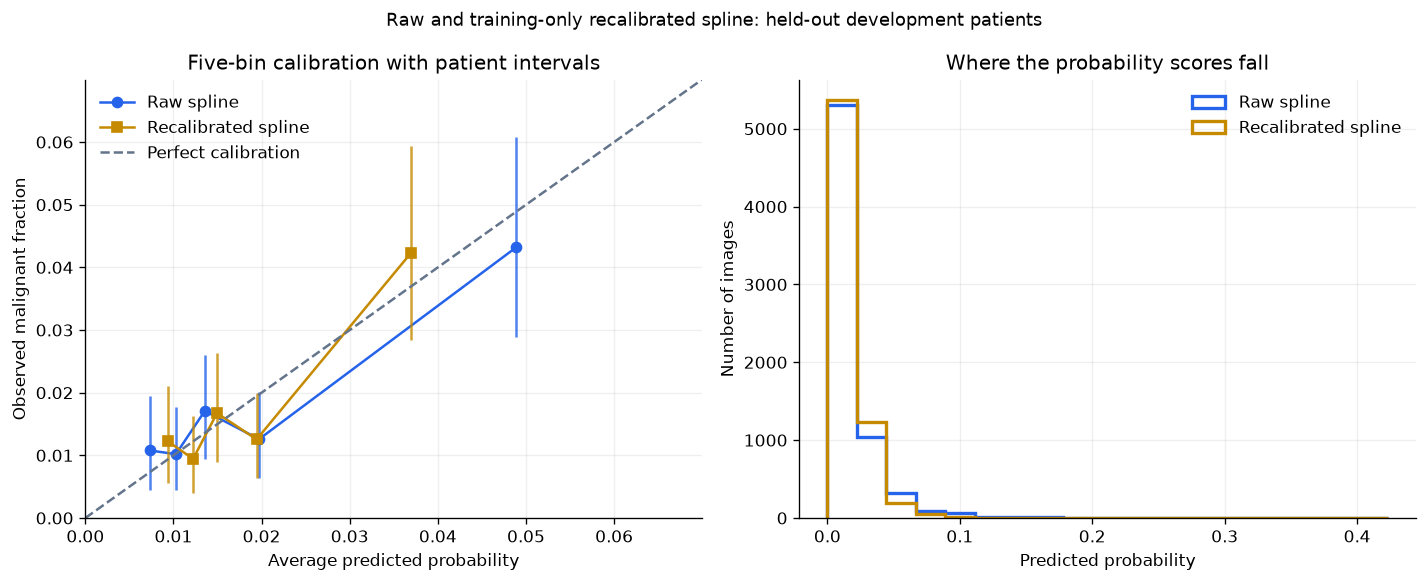

,model,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,observed_lower,observed_upper
0,Raw spline,1,1391,15,0.0073,0.0108,0.0026,0.0089,120,0.0044,0.0194
1,Raw spline,2,1374,14,0.0103,0.0102,0.0090,0.0115,157,0.0045,0.0177
2,Raw spline,3,1405,24,0.0136,0.0171,0.0116,0.0160,201,0.0094,0.0260
3,Raw spline,4,1351,17,0.0197,0.0126,0.0161,0.0259,204,0.0064,0.0201
4,Raw spline,5,1343,58,0.0489,0.0432,0.0261,0.4223,195,0.0289,0.0608
5,Recalibrated spline,1,1384,17,0.0093,0.0123,0.0040,0.0109,118,0.0055,0.0210
6,Recalibrated spline,2,1378,13,0.0122,0.0094,0.0109,0.0134,167,0.0040,0.0162
7,Recalibrated spline,3,1374,23,0.0149,0.0167,0.0134,0.0168,179,0.0090,0.0264
8,Recalibrated spline,4,1355,17,0.0194,0.0125,0.0169,0.0239,215,0.0064,0.0199
9,Recalibrated spline,5,1373,58,0.0369,0.0422,0.0239,0.2522,196,0.0284,0.0593


,procedure,average_precision,roc_auc,log_loss,brier
0,Raw spline,0.04837,0.64986,0.08974,0.01814
1,Recalibrated spline,0.04779,0.64597,0.08955,0.01812


In [6]:
def bin_rate_intervals(frame, probabilities, bins, repetitions=2000):
    rng = np.random.default_rng(42)
    groups, codes = np.unique(frame.patient_id.to_numpy(), return_inverse=True)
    draws = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=repetitions)
    records = []
    for row in bins.itertuples():
        inside = (probabilities >= row.min_probability) & (probabilities <= row.max_probability)
        totals = np.bincount(codes, weights=inside.astype(float), minlength=len(groups))
        positives = np.bincount(codes, weights=inside * frame.target.to_numpy(), minlength=len(groups))
        denominators = draws @ totals
        rates = np.divide(draws @ positives, denominators, out=np.full(repetitions, np.nan), where=denominators > 0)
        finite = rates[np.isfinite(rates)]
        lower, upper = np.quantile(finite, [0.025, 0.975])
        records.append({"bin": row.bin, "observed_lower": lower, "observed_upper": upper})
    return pd.DataFrame(records)

calibration_tables = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.9))
for name, color, marker in [("Raw spline", "#2563EB", "o"), ("Recalibrated spline", "#C58A00", "s")]:
    probabilities = probability_sets[name]
    bins = calibration_bins(train.target, probabilities, n_bins=5, groups=train.patient_id)
    bins = bins.merge(bin_rate_intervals(train, probabilities, bins), on="bin", validate="one_to_one")
    bins.insert(0, "model", name)
    calibration_tables.append(bins)
    axes[0].plot(bins.mean_probability, bins.observed_rate, marker=marker, color=color, label=name)
    axes[0].vlines(bins.mean_probability, bins.observed_lower, bins.observed_upper, color=color, alpha=0.8)
    axes[1].hist(probabilities, bins=np.linspace(0, max(probability_sets["Raw spline"].max(), probability_sets["Recalibrated spline"].max()) + .001, 20), histtype="step", linewidth=2, color=color, label=name)
calibration_table = pd.concat(calibration_tables, ignore_index=True)
calibration_table.to_csv(TABLES / "metadata_calibration_bins_d1.csv", index=False)
limit = max(calibration_table.mean_probability.max(), calibration_table.observed_upper.max()) * 1.15
axes[0].plot([0, limit], [0, limit], linestyle="--", color="#64748B", label="Perfect calibration")
axes[0].set(xlim=(0, limit), ylim=(0, limit), xlabel="Average predicted probability", ylabel="Observed malignant fraction", title="Five-bin calibration with patient intervals")
axes[1].set(xlabel="Predicted probability", ylabel="Number of images", title="Where the probability scores fall")
for axis in axes:
    axis.legend(frameon=False); axis.grid(alpha=0.2)
fig.suptitle("Raw and training-only recalibrated spline: held-out development patients", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_calibration_d1.png", dpi=180, bbox_inches="tight")
plt.show()
display(calibration_table.round(4))
display(pd.DataFrame([{"procedure": name, **probability_metrics(train.target, probability_sets[name])}
                      for name in ["Raw spline", "Recalibrated spline"]]).round(5))

### 6. Assess the cutoff trade-off on outer patients

Each outer fold keeps the cutoff selected from its own training data. We combine those decisions without choosing a more favourable cutoff from the outer labels.

In the first table, TP and FN count malignant images found and missed; FP and TN count benign images flagged and left unflagged. Sensitivity is the fraction of malignant images found, specificity is the fraction of benign images left unflagged, and precision is the fraction of flagged images that are malignant. The flagged fraction shows the review workload.

The second table gives 95% patient-bootstrap intervals for those proportions. These keep the saved decisions fixed rather than reselecting a cutoff in each draw. The raw and recalibrated procedures make the same decisions in this run: they find 102 of 128 malignant images and flag 4,599 of 6,864 images.


In [7]:
def decision_intervals(frame, decisions, repetitions=2000, seed=42):
    groups, codes = np.unique(frame.patient_id.to_numpy(), return_inverse=True)
    targets = frame.target.to_numpy()
    decisions = np.asarray(decisions, dtype=bool)
    quantities = np.array([
        np.bincount(codes, weights=(targets == 1) & decisions, minlength=len(groups)),
        np.bincount(codes, weights=(targets == 1) & ~decisions, minlength=len(groups)),
        np.bincount(codes, weights=(targets == 0) & ~decisions, minlength=len(groups)),
        np.bincount(codes, weights=(targets == 0) & decisions, minlength=len(groups)),
    ])
    rng = np.random.default_rng(seed)
    draws = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=repetitions)
    tp, fn, tn, fp = quantities @ draws.T
    ratios = {"sensitivity": (tp, tp + fn), "specificity": (tn, tn + fp),
              "precision": (tp, tp + fp), "flagged_fraction": (tp + fp, tp + fn + tn + fp)}
    points = decision_metrics(targets, decisions)
    records = []
    for metric, (numerator, denominator) in ratios.items():
        values = np.divide(numerator, denominator, out=np.full(repetitions, np.nan), where=denominator > 0)
        finite = values[np.isfinite(values)]
        lower, upper = np.quantile(finite, [0.025, 0.975]) if len(finite) else (np.nan, np.nan)
        records.append({"metric": metric, "estimate": points[metric], "ci_lower": lower, "ci_upper": upper, "n_valid": len(finite)})
    return pd.DataFrame(records)

decision_rows, decision_ci_tables = [], []
for name, column in [("Raw spline", "decision_raw"), ("Recalibrated spline", "decision_calibrated")]:
    decision_rows.append({"procedure": name, **decision_metrics(train.target, outer_predictions[column])})
    ci = decision_intervals(train, outer_predictions[column]); ci.insert(0, "procedure", name)
    decision_ci_tables.append(ci)
decision_summary = pd.DataFrame(decision_rows)
decision_ci = pd.concat(decision_ci_tables, ignore_index=True)
decision_summary.to_csv(METRICS / "metadata_nested_threshold_metrics_d1.csv", index=False)
decision_ci.to_csv(METRICS / "metadata_nested_threshold_intervals_d1.csv", index=False)
display(decision_summary.round(4))
display(decision_ci.round(4))

,procedure,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,Raw spline,102,4497,2239,26,0.7969,0.3324,0.0222,0.67
1,Recalibrated spline,102,4497,2239,26,0.7969,0.3324,0.0222,0.67


,procedure,metric,estimate,ci_lower,ci_upper,n_valid
0,Raw spline,sensitivity,0.7969,0.7130,0.8786,2000
1,Raw spline,specificity,0.3324,0.2826,0.3887,2000
2,Raw spline,precision,0.0222,0.0166,0.0285,2000
3,Raw spline,flagged_fraction,0.6700,0.6142,0.7190,2000
4,Recalibrated spline,sensitivity,0.7969,0.7130,0.8786,2000
5,Recalibrated spline,specificity,0.3324,0.2826,0.3887,2000
6,Recalibrated spline,precision,0.0222,0.0166,0.0285,2000
7,Recalibrated spline,flagged_fraction,0.6700,0.6142,0.7190,2000


### 7. Read the age, sex and site checks

Each group uses raw spline scores and one common training-selected cutoff procedure. No group-specific cutoff is tuned. Age bands below 50 and 50 or older are fixed reporting groups.

The three panels show age, sex and site. Rows name groups; horizontal position is AP, with larger values meaning better ranking. Blue circles are observed AP and lines are 95% intervals from 1,000 patient draws within the group. Labels count patients with a malignant image. Crosses mark fewer than ten such patients, with intervals suppressed; `AP undefined` means no malignant images to assess ranking.

Check counts, malignant share and sensitivity in the table before comparing groups. AP depends partly on how common malignancy is, so it cannot establish fairness alone. Sparse groups and wide intervals limit conclusions, and one patient can appear in multiple age or site groups.


,field,group,images,patients,positive_images,positive_patients,prevalence,average_precision,average_precision_lower,average_precision_upper,sensitivity,evidence_note
0,Age band,<50,3089,189,32,23,0.0104,0.0123,0.0074,0.0262,0.4375,Exploratory; no subgroup tuning
1,Age band,>=50,3775,269,96,65,0.0254,0.0645,0.0410,0.1157,0.9167,Exploratory; no subgroup tuning
2,Sex,female,3553,204,53,37,0.0149,0.0334,0.0203,0.0809,0.6792,Exploratory; no subgroup tuning
3,Sex,male,3311,218,75,51,0.0227,0.0620,0.0356,0.1155,0.8800,Exploratory; no subgroup tuning
4,Site,Unknown,196,53,2,2,0.0102,0.0778,NaN,NaN,1.0000,Sparse: intervals suppressed
5,Site,head/neck,409,179,21,21,0.0513,0.1398,0.0648,0.3140,1.0000,Exploratory; no subgroup tuning
6,Site,lower extremity,1650,327,25,23,0.0152,0.0460,0.0152,0.0946,0.7200,Exploratory; no subgroup tuning
7,Site,oral/genital,33,20,3,2,0.0909,0.0842,NaN,NaN,1.0000,Sparse: intervals suppressed
8,Site,palms/soles,70,40,0,0,0.0000,NaN,NaN,NaN,NaN,Sparse: intervals suppressed
9,Site,torso,3440,398,54,41,0.0157,0.0377,0.0209,0.0688,0.6852,Exploratory; no subgroup tuning


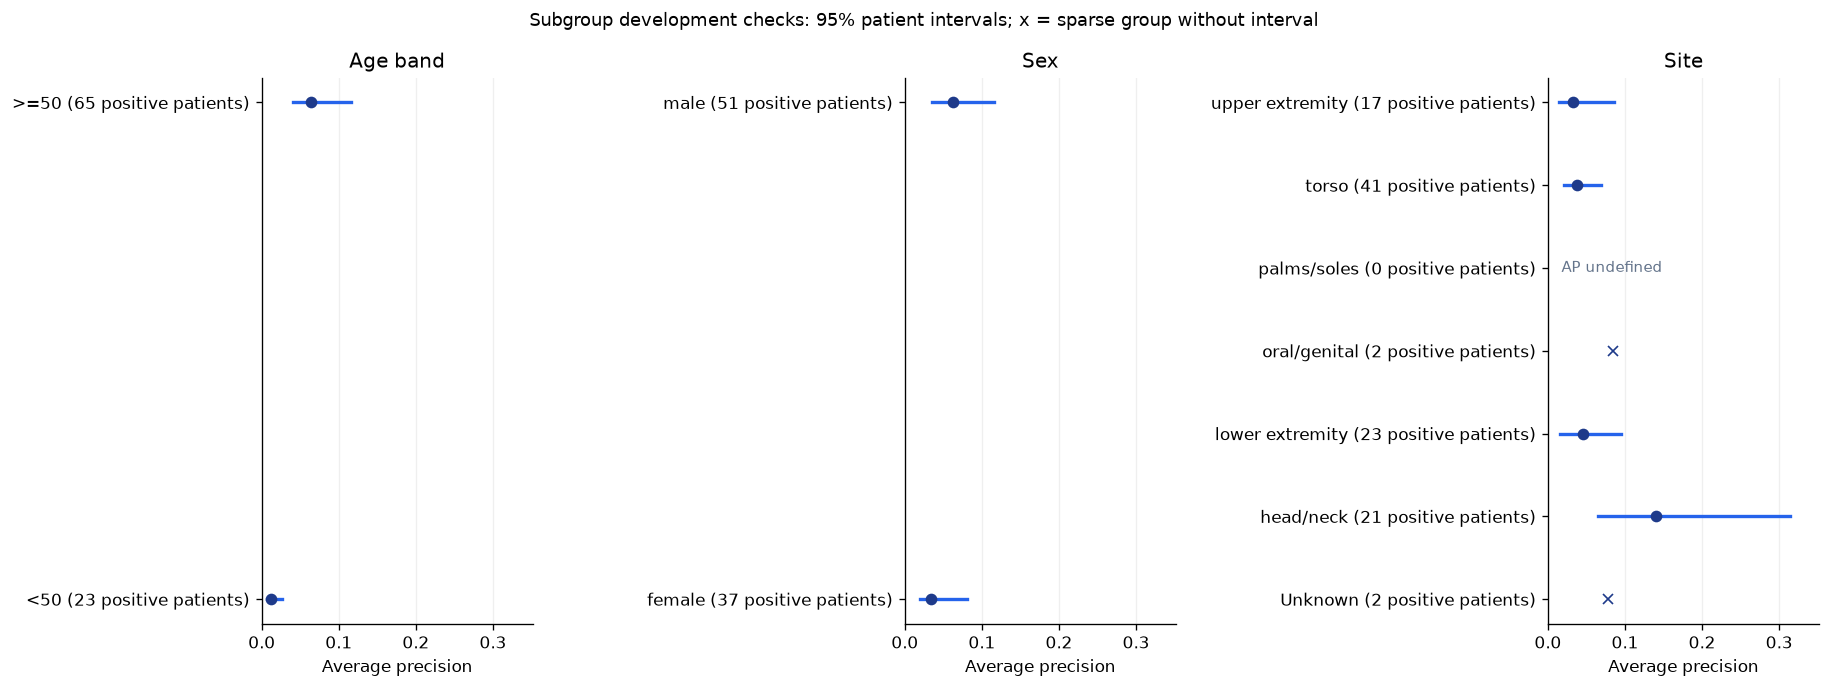

In [8]:
ages = pd.to_numeric(train.age_approx, errors="coerce")
age_groups = pd.Series(np.where(ages.isna(), "Missing", np.where(ages < 50, "<50", ">=50")), index=train.index)
report_groups = {
    "Age band": age_groups,
    "Sex": train.sex.fillna("Missing").astype(str),
    "Site": train.anatom_site_general_challenge.fillna("Missing").astype(str),
}
subgroup_rows = []
for field, labels in report_groups.items():
    for label in sorted(labels.unique()):
        mask = labels.eq(label).to_numpy()
        subset = train.loc[mask].reset_index(drop=True)
        probabilities = outer_predictions.loc[mask, "p_spline_raw"].to_numpy()
        decisions = outer_predictions.loc[mask, "decision_raw"].to_numpy()
        positive_patients = int(subset.groupby("patient_id").target.max().sum())
        row = {"field": field, "group": label, "images": len(subset), "patients": subset.patient_id.nunique(),
               "positive_images": int(subset.target.sum()), "positive_patients": positive_patients,
               "prevalence": subset.target.mean(), **probability_metrics(subset.target, probabilities),
               **decision_metrics(subset.target, decisions),
               "evidence_note": "Sparse: intervals suppressed" if positive_patients < 10 else "Exploratory; no subgroup tuning"}
        for metric in ["average_precision", "roc_auc", "sensitivity"]:
            row[f"{metric}_lower"] = np.nan; row[f"{metric}_upper"] = np.nan
        if positive_patients >= 10 and subset.target.nunique() == 2:
            group_ci = patient_bootstrap(subset.target, subset.patient_id, {"Raw spline": probabilities}, n_bootstrap=1000, seed=42)
            for metric in ["average_precision", "roc_auc"]:
                result = group_ci[group_ci.metric.eq(metric)].iloc[0]
                row[f"{metric}_lower"] = result.ci_lower; row[f"{metric}_upper"] = result.ci_upper
            result = decision_intervals(subset, decisions, repetitions=1000).query("metric == 'sensitivity'").iloc[0]
            row["sensitivity_lower"] = result.ci_lower; row["sensitivity_upper"] = result.ci_upper
        subgroup_rows.append(row)
subgroup_table = pd.DataFrame(subgroup_rows)
subgroup_table.to_csv(TABLES / "metadata_subgroup_checks_d1.csv", index=False)
display(subgroup_table[["field", "group", "images", "patients", "positive_images", "positive_patients", "prevalence", "average_precision", "average_precision_lower", "average_precision_upper", "sensitivity", "evidence_note"]].round(4))

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.8), sharex=True)
subgroup_maximum = max(subgroup_table.average_precision.max(), subgroup_table.average_precision_upper.max()) * 1.12
for axis, field in zip(axes, report_groups):
    rows = subgroup_table[subgroup_table.field.eq(field)].reset_index(drop=True)
    for index, row in rows.iterrows():
        if pd.notna(row.average_precision_lower):
            axis.plot([row.average_precision_lower, row.average_precision_upper], [index, index], color="#2563EB", linewidth=2)
        axis.plot(row.average_precision, index, "o" if row.positive_patients >= 10 else "x", color="#1E3A8A")
        if pd.isna(row.average_precision):
            axis.text(subgroup_maximum * .05, index, "AP undefined", va="center", fontsize=9, color="#64748B")
    axis.set_yticks(range(len(rows)), [f"{row.group} ({row.positive_patients} positive patients)" for row in rows.itertuples()])
    axis.set_title(field); axis.set_xlabel("Average precision"); axis.set_xlim(0, subgroup_maximum); axis.grid(axis="x", alpha=0.2)
fig.suptitle("Subgroup development checks: 95% patient intervals; x = sparse group without interval", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "metadata_subgroups_d1.png", dpi=180, bbox_inches="tight")
plt.show()

### 8. Record the final-fit boundary

The original workflow previously created an all-development spline bundle. That historical artifact is preserved, while this updated report keeps fitting outside notebook execution. A newly tuned NN has its own preprocessing and predictions; the spline's probability calibration and recall cutoff cannot be attached to it. Choosing a final procedure requires an explicit decision about its settings, calibration and threshold before any independent test is opened.

The cell records this boundary only. The current experiment compares patient-held-out development predictions and produces no all-development model or reserved-test evaluation.

In [9]:
print("Report only: no final all-development fit or reserved-test evaluation is performed.")

Report only: no final all-development fit or reserved-test evaluation is performed.


### 9. Check the results together

The printed recap below brings together the AP comparison, its uncertainty interval, the cutoff's detection and review workload, and the number of sparse reporting groups. Read these as development findings for the retained spline.


In [10]:
raw_ap = probability_metrics(train.target, probability_sets["Raw spline"])["average_precision"]
nn_ap = probability_metrics(train.target, probability_sets["Fixed NN mean of three"])["average_precision"]
delta = intervals[(intervals.model_name == "Fixed NN mean of three") & (intervals.reference_model == "Raw spline") & (intervals.metric == "average_precision")].iloc[0]
raw_decisions = decision_summary.query("procedure == 'Raw spline'").iloc[0]
print(f"Raw spline AP: {raw_ap:.4f}; mean-of-three NN AP: {nn_ap:.4f}.")
print(f"NN minus spline AP: {delta.estimate:+.4f}, patient 95% interval [{delta.ci_lower:+.4f}, {delta.ci_upper:+.4f}].")
print(f"Training-target recall: {TARGET_RECALL:.0%}; held-out raw-spline sensitivity: {raw_decisions.sensitivity:.1%}.")
print(f"At that policy, {raw_decisions.flagged_fraction:.1%} of images are flagged; precision is {raw_decisions.precision:.1%}.")
print(f"Sparse reporting groups: {int(subgroup_table.positive_patients.lt(10).sum())} of {len(subgroup_table)}.")
print("Historical fixed-model diagnostics; the added tuned-NN comparison is reported below. The final test remains closed.")

Raw spline AP: 0.0484; mean-of-three NN AP: 0.0465.
NN minus spline AP: -0.0019, patient 95% interval [-0.0190, +0.0059].
Training-target recall: 80%; held-out raw-spline sensitivity: 79.7%.
At that policy, 67.0% of images are flagged; precision is 2.2%.
Sparse reporting groups: 3 of 11.
Historical fixed-model diagnostics; the added tuned-NN comparison is reported below. The final test remains closed.


## Limitations

These folds have already guided model comparisons. Keeping calibration and cutoff selection within training prevents direct outer-label reuse for those steps, but cannot undo earlier model exploration. Independent final testing is still needed after decisions are fixed.

Bootstrap intervals hold predictions and decisions fixed. They cover patient-sampling variation, without including retraining, method selection or a new hospital. Multiple exploratory comparisons are not adjusted for repeated testing.

Only 128 images are malignant; three of eleven reporting groups have fewer than ten patients with a malignant image. AP changes with malignant prevalence, and sparse subgroup results cannot establish fairness or causation. Five calibration bins can hide within-bin differences.

The 80% recall target is an academic scenario. Flagging two-thirds of images does not establish acceptable clinical workload or safety. The metadata model predicts image outcomes without seeing lesion appearance.


## Summary

The raw spline has AP 0.0484; the three-network mean has AP 0.0465. Their difference is -0.0019 with a 95% patient-bootstrap interval of [-0.0190, +0.0059], giving no clear network improvement. Recalibration slightly lowers probability error and pooled ranking scores; its cutoff decisions match the raw spline here.

Keep the raw spline as primary. The training-selected 80% recall scenario finds 79.7% of malignant images, flags 67.0% of all images and has 2.2% precision. That workload limits metadata alone, and sparse groups need caution.

The fitted spline and cutoff are saved; the reserved test has not been evaluated. Next, [09_image_b0_pilot.ipynb](09_image_b0_pilot.ipynb) explores image information. Complete and freeze modelling decisions before final testing.


**Historical fixed-model summary:** read the separately declared version-2 assessment below for the current ROC-AUC-first model comparison.

### Additional ROC-AUC-selected metadata experiment

The new experiment selects spline, Random Forest, XGBoost and NN settings by unweighted mean inner-fold ROC-AUC, with preprocessing and duration selection confined to outer-training patients. The completed earlier experiment remains AP-selected history; it is not retrospectively described as ROC-AUC-tuned. The new three-seed network still trains with binary cross-entropy and selects its duration using stopping loss. Its probabilities are averaged before scoring.

Mean outer-fold ROC-AUC is the primary model comparison. Mean outer-fold AP, log loss and Brier score are secondary; pooled metrics are supporting summaries. These are image-level metrics within patient-held-out folds, not patient-level diagnoses. Original results retain duplicate-bearing development records; the deduplicated condition supplies the main clean-data evidence.

The paired comparisons use 2,000 whole-patient resamples within each preserved outer fold. Every model receives the same draw. The intervals condition on saved predictions and do not include repeating the complete fitting and selection process. An interval containing zero leaves the difference unresolved and does not establish equivalence. An observed leading score does not prove superiority.

This is an additional development experiment after earlier outer-fold findings were examined. The revised objective and search were frozen before execution, without expanding the grid in response to new outer scores. Historical calibration maps and recall cutoffs remain attached to their original fixed procedures; they cannot be transferred to the newly ROC-selected NN or spline. This appendix does not replace the final model, fit an all-development model or open the reserved test.


,model,roc_auc,average_precision,log_loss,brier
54,nn_tuned,0.680946,0.067425,0.088630,0.018077
47,nn_mean,0.678785,0.058119,0.088960,0.018101
12,spline_tuned,0.673912,0.068474,0.089426,0.018098
5,spline,0.662886,0.064855,0.089737,0.018137


,comparison,metric,difference,ci_lower,ci_upper
1,nn_tuned minus fixed_nn,roc_auc,0.002161,-0.007395,0.010452
9,nn_tuned minus fixed_spline,roc_auc,0.018060,-0.008548,0.037686
17,nn_tuned minus tuned_spline,roc_auc,0.007034,-0.023803,0.028666
0,nn_tuned minus fixed_nn,average_precision,0.009306,-0.001239,0.029473
8,nn_tuned minus fixed_spline,average_precision,0.002570,-0.007512,0.014223
16,nn_tuned minus tuned_spline,average_precision,-0.001049,-0.012699,0.007660
2,nn_tuned minus fixed_nn,log_loss,-0.000330,-0.000852,0.000268
10,nn_tuned minus fixed_spline,log_loss,-0.001108,-0.002692,0.000538
18,nn_tuned minus tuned_spline,log_loss,-0.000796,-0.002234,0.000879
3,nn_tuned minus fixed_nn,brier,-0.000024,-0.000060,0.000013


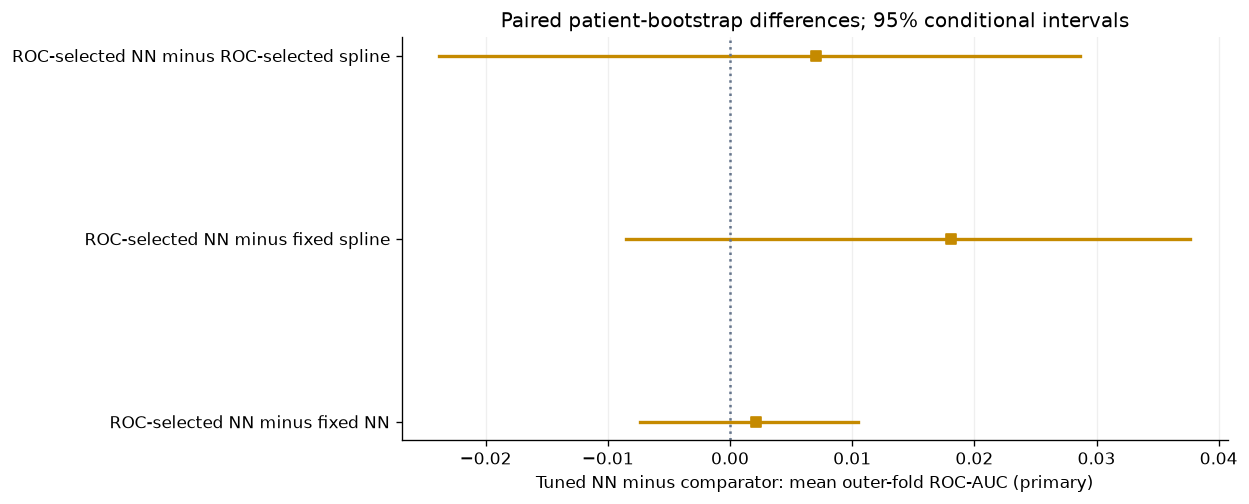

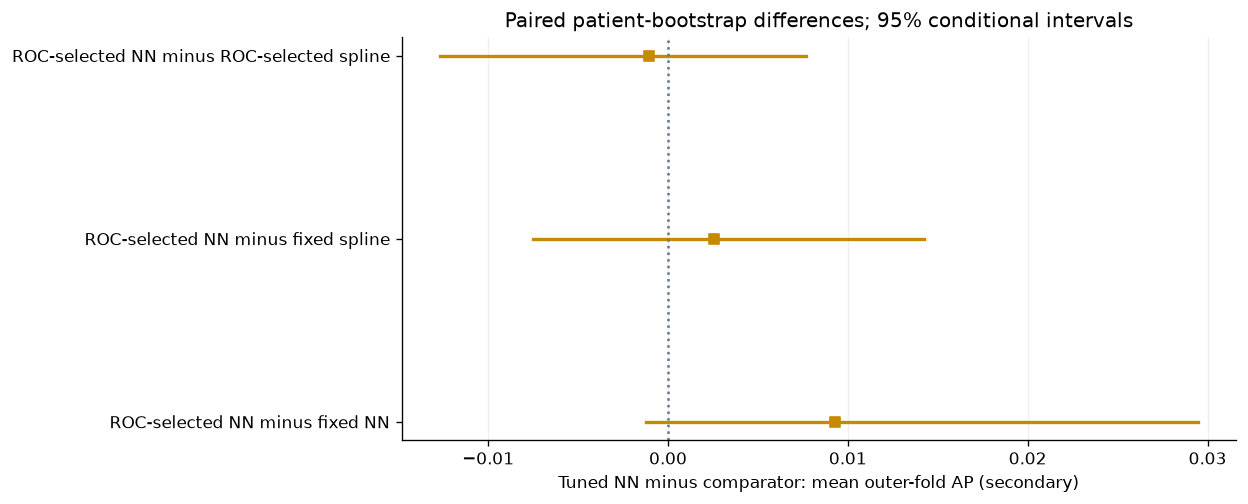

**Observed primary comparison:** fixed spline ROC-AUC 0.6629; ROC-selected NN ROC-AUC 0.6809. The mean-fold difference is +0.0181, with a 95% conditional patient interval [-0.0085, +0.0377]. Read secondary AP and probability losses alongside the primary result. Model choice remains an explicit decision; no calibration map, cutoff or final fitted model is produced for the newly tuned procedures.

In [11]:
from melanoma_detection.metadata_tuning_v2_evaluation import show_assessment
import matplotlib.pyplot as plt
plt.rcdefaults()
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
show_assessment(PROJECT_ROOT, 'original', run_id='roc_auc_grid36_v1', experiment_version=2)